# TP2 – Modèle de langage neuronal (MLP) : exécutions sur Colab

## Étape 1 – Vérifier le GPU

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch
print("torch", torch.__version__, "| GPU :", torch.cuda.is_available())

name, memory.total [MiB]
Tesla T4, 15360 MiB
torch 2.14.1+cu130 | GPU : True


## Étape 2 – Monter le Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive/Projet_MLP'
import os
assert os.path.exists(f'{DRIVE}/Projet_MLP_colab.zip'), f"Projet_MLP_colab.zip introuvable dans {DRIVE}"
os.makedirs(f'{DRIVE}/resultats', exist_ok=True)
print(sorted(os.listdir(DRIVE)))

Mounted at /content/drive
['Projet_MLP.ipynb', 'Projet_MLP_colab.zip', 'resultats']


## Étape 3 – Installer le projet sur le disque local

In [4]:
%%bash
set -e
rm -rf /content/Projet_MLP
mkdir -p /content/Projet_MLP
cd /content/Projet_MLP
unzip -q /content/drive/MyDrive/Projet_MLP/Projet_MLP_colab.zip
ln -s /content/drive/MyDrive/Projet_MLP/resultats resultats
ls
echo "--- donnees/"; ls donnees
echo "--- resultats/ (Drive)"; ls resultats

common.py
donnees
genere.py
model.py
perplexite.py
README.md
remplis_trous.py
resultats
sgns.py
similarite.py
train.py
Vocab.py
--- donnees/
bpe_embeddings_12k_32.txt
file_1.mask
file_2.mask
file_3.mask
Le_comte_de_Monte_Cristo.100.sim
sim_couverts84.sim
sim_inconnus16.sim
test_12k.bpe
test_12k.mask
tokens_candidats_textes_a_trou_12k
train_12k.bpe
val_12k.bpe
--- resultats/ (Drive)


In [5]:
%cd /content/Projet_MLP

/content/Projet_MLP


## Étape 4 – Questions 3.1 à 3.3 : entraînement du modèle de base

In [7]:
%%bash
set -o pipefail
if [ -f resultats/mlp_base_history.json ]; then echo "mlp_base déjà entraîné"; else
  python -u train.py --train donnees/train_12k.bpe --val donnees/val_12k.bpe --emb_file donnees/bpe_embeddings_12k_32.txt --out resultats/mlp_base.pt 2>&1 | tee resultats/train_base.log
fi

device : cuda
11844 32
donnees/train_12k.bpe : 156542 phrases, 4683231 tokens, 4213605 exemples
donnees/val_12k.bpe : 19568 phrases, 580004 tokens, 521300 exemples
|V|=11844 d=32 k=3 dh=256 | paramètres entraînables : 3,068,740
epoch 0 | val 13.5352 bits (PP 11871.00)
  epoch 1 :   5 % | perte 7.643 bits | reste ~0.8 min
  epoch 1 :  10 % | perte 7.160 bits | reste ~0.7 min
  epoch 1 :  15 % | perte 6.881 bits | reste ~0.7 min
  epoch 1 :  20 % | perte 6.695 bits | reste ~0.6 min
  epoch 1 :  25 % | perte 6.557 bits | reste ~0.6 min
  epoch 1 :  30 % | perte 6.448 bits | reste ~0.6 min
  epoch 1 :  35 % | perte 6.359 bits | reste ~0.5 min
  epoch 1 :  40 % | perte 6.285 bits | reste ~0.5 min
  epoch 1 :  45 % | perte 6.226 bits | reste ~0.4 min
  epoch 1 :  50 % | perte 6.175 bits | reste ~0.4 min
  epoch 1 :  55 % | perte 6.129 bits | reste ~0.3 min
  epoch 1 :  60 % | perte 6.092 bits | reste ~0.3 min
  epoch 1 :  65 % | perte 6.058 bits | reste ~0.3 min
  epoch 1 :  70 % | perte 6.0

## Étape 5 – Question 4.1 : perplexité sur le test

In [8]:
!python -u perplexite.py resultats/mlp_base.pt donnees/test_12k.bpe 2>&1 | tee resultats/perplexite_base.log

11844 32
donnees/test_12k.bpe : 19568 phrases, 584689 tokens, 525985 exemples
entropie croisée : 5.4755 bits/token
log2(perplexité) : 5.4755   (valeur demandée par le sujet, = entropie croisée)
perplexité       : 44.49
perplexité sans les </s> de remplissage : 60.37 (39136 cibles triviales retirées sur 525985)


## Étape 6 – Question 4.2 : textes à trous (rang normalisé)

In [9]:
%%bash
MASKS="donnees/file_1.mask donnees/file_2.mask donnees/file_3.mask"
CANDS=donnees/tokens_candidats_textes_a_trou_12k/
python -u remplis_trous.py resultats/mlp_base.pt $MASKS --candidats $CANDS > resultats/trous_base.log 2>&1
python -u remplis_trous.py resultats/mlp_base.pt $MASKS --candidats $CANDS --contexte gauche > resultats/trous_base_gauche.log 2>&1
head -14 resultats/trous_base.log
echo ...
tail -1 resultats/trous_base.log
tail -1 resultats/trous_base_gauche.log

11844 32

donnees/file_1.mask : trou n°20 -> réponse « testament »   ... naître , à quoi bon un [testament] ? </s> </s> </s> </s> </s> ...
  ensemble_1.txt : rang 4/100  rang normalisé 0.970 (réponse ajoutée)  | meilleurs : homme vin sage testament billet
  ensemble_10.txt : rang 1/100  rang normalisé 1.000 (réponse ajoutée)  | meilleurs : testament ennui fruit boeuf géant
  ensemble_2.txt : rang 1/100  rang normalisé 1.000 (réponse ajoutée)  | meilleurs : testament palais groupe traître géant
  ensemble_3.txt : rang 2/100  rang normalisé 0.990 (réponse ajoutée)  | meilleurs : souci testament royaume groupe colonel
  ensemble_4.txt : rang 3/100  rang normalisé 0.980 (réponse ajoutée)  | meilleurs : malheur malheureux testament jardin régiment
  ensemble_5.txt : rang 4/100  rang normalisé 0.970 (réponse ajoutée)  | meilleurs : drôle talent ordre testament cache
  ensemble_6.txt : rang 4/100  rang normalisé 0.970 (réponse ajoutée)  | meilleurs : ami fou caprice testament cela
  ensemble_

## Étape 7 – Question 4.3 : génération de texte

In [10]:
!python -u genere.py resultats/mlp_base.pt --n 10 --seed 0 2>&1 | tee resultats/generation_base.log

11844 32
oui , chère , je ne vous pas fait ?
et , dans un ton drapé ayant troucé des dieux .
il comprenait .
le car cela , tous les autres ?
puis , ne gardant rien il était si très bête et mon père ne frère le plus de ce monde de battre sa mère .
ce sera son rêve , il regardait , éperdue au milieu de leurs ailes .
elle faut boire le vice .
je n ' ai consenti d ' accordtes , par des places élevé du marché possible , de plaisir sur la bourse de nos deux frères d ' ailleurs .
elle repassa , un coupe sous les bras en éclaboussé dans sa cuisine de place !
albine s ' était levé dans les poings , les fortifications , dis donc , mon dieu .


In [11]:
# Variantes : température plus basse (plus prudent) ou début de phrase imposé (tokens BPE)
!python -u genere.py resultats/mlp_base.pt --n 5 --seed 0 --temperature 0.7
!python -u genere.py resultats/mlp_base.pt --n 5 --seed 0 --debut "il"

11844 32
je t ' avais , la situation entière , et ceux des berges et d ' une averse de jour .
ça l ' entouraient , en deux deux filles , ils ont les autres ?
puis , ne gardant plus rien , c ' est le plaisir de ne pas arriver plus de ce monde de la chute , le palais , arriva , les compagnons se trouvaient , les rideaux , où les évosions du coeur !
c ' était une fièvre de figues , d ' autres qui n ' avait plus élevé à terre possible , de la maison !
et , comme quand elle avait conscience de l ' ombre était trop , malgré le ciel .
11844 32
il n ' espérait aucun vers la porte , à pierre , des façades de petits d ' homme ayant supérieure comme une des fils .
il partit sur le jardin , car cela , tous les autres ?
il venait de ne pas l ' habitude au sujet du petit coup de balai , le plus de ce monde de battre sa mère .
il défendait que son rêve avait fait , qu ' il renît ses évosions du coeur !
il y occupait un air de paupières .


## Étape 8 – Piste 1 : embeddings appris par le modèle (initialisation aléatoire)

Même modèle, mais la matrice E est un paramètre entraîné (`--train_emb`), partant d'une matrice aléatoire (`--init random`).

In [12]:
%%bash
set -o pipefail
if [ -f resultats/mlp_emb_random_history.json ]; then echo "mlp_emb_random déjà entraîné"; else
  python -u train.py --train donnees/train_12k.bpe --val donnees/val_12k.bpe --emb_file donnees/bpe_embeddings_12k_32.txt --init random --train_emb --out resultats/mlp_emb_random.pt 2>&1 | tee resultats/train_emb_random.log
fi

device : cuda
11844 32
donnees/train_12k.bpe : 4213605 exemples (cache)
donnees/val_12k.bpe : 521300 exemples (cache)
|V|=11844 d=32 k=3 dh=256 | paramètres entraînables : 3,447,748
epoch 0 | val 13.5946 bits (PP 12370.31)
  epoch 1 :   5 % | perte 7.850 bits | reste ~1.0 min
  epoch 1 :  10 % | perte 7.448 bits | reste ~0.8 min
  epoch 1 :  15 % | perte 7.215 bits | reste ~0.8 min
  epoch 1 :  20 % | perte 7.059 bits | reste ~0.7 min
  epoch 1 :  25 % | perte 6.943 bits | reste ~0.7 min
  epoch 1 :  30 % | perte 6.844 bits | reste ~0.6 min
  epoch 1 :  35 % | perte 6.762 bits | reste ~0.6 min
  epoch 1 :  40 % | perte 6.691 bits | reste ~0.5 min
  epoch 1 :  45 % | perte 6.631 bits | reste ~0.5 min
  epoch 1 :  50 % | perte 6.577 bits | reste ~0.4 min
  epoch 1 :  55 % | perte 6.529 bits | reste ~0.4 min
  epoch 1 :  60 % | perte 6.486 bits | reste ~0.3 min
  epoch 1 :  65 % | perte 6.447 bits | reste ~0.3 min
  epoch 1 :  70 % | perte 6.411 bits | reste ~0.3 min
  epoch 1 :  75 % | p

## Étape 9 – Embeddings SGNS (nécessaires aux pistes 2 et 3)

Algorithme du TP1 (config « all ») sur le corpus BPE, même vocabulaire et même dimension (32) que le MLP
→ `resultats/sgns_32.txt`.

In [13]:
%%bash
set -o pipefail
if [ -f resultats/sgns_32.txt ]; then echo "sgns_32.txt déjà calculé"; else
  python -u sgns.py --corpus donnees/train_12k.bpe --emb_file donnees/bpe_embeddings_12k_32.txt 2>&1 | tee resultats/sgns_32.log
fi

device : cuda
11844 32
donnees/train_12k.bpe : 156542 phrases, 4057063 tokens
epoch 1 : 59% des tokens gardés, 6,606,203 paires
   10 % | perte 3.9809 | 4s
   20 % | perte 3.6194 | 5s
   30 % | perte 3.4570 | 5s
   40 % | perte 3.3516 | 6s
   50 % | perte 3.2764 | 6s
   60 % | perte 3.2211 | 7s
   70 % | perte 3.1783 | 7s
   80 % | perte 3.1442 | 8s
   90 % | perte 3.1164 | 8s
  100 % | perte 3.0934 | 9s
epoch 1 | perte moyenne 3.0930
          il : elle on hélène pourtant jeanne enfin silvine albine
      maison : chambre ville place famille vallée bourse boutique salle
       rouge : jaune sombre pâle souple blanc noir grise humide
         dit : répondit murmurait répéta continua répétait reprit ajouta murmura
        deux : trois quatre cinq placés plusieurs quatorze douze dernières
       paris : sedan rouen magique intervalle plassans sud jugement rome
epoch 2 : 59% des tokens gardés, 6,610,490 paires
   10 % | perte 2.8535 | 0s
   20 % | perte 2.8545 | 1s
   30 % | perte 2.8545 

## Étape 10 – Piste 3 : embeddings appris, initialisés avec SGNS

Comme la piste 1, mais E part des vecteurs SGNS (`--init_from`).

In [14]:
%%bash
set -o pipefail
if [ -f resultats/mlp_emb_sgns_history.json ]; then echo "mlp_emb_sgns déjà entraîné"; else
  python -u train.py --train donnees/train_12k.bpe --val donnees/val_12k.bpe --emb_file donnees/bpe_embeddings_12k_32.txt --init_from resultats/sgns_32.txt --train_emb --out resultats/mlp_emb_sgns.pt 2>&1 | tee resultats/train_emb_sgns.log
fi

device : cuda
11844 32
donnees/train_12k.bpe : 4213605 exemples (cache)
donnees/val_12k.bpe : 521300 exemples (cache)
11844 32
init depuis resultats/sgns_32.txt : 11844/11844 tokens trouvés
|V|=11844 d=32 k=3 dh=256 | paramètres entraînables : 3,447,748
epoch 0 | val 13.5206 bits (PP 11751.73)
  epoch 1 :   5 % | perte 7.428 bits | reste ~0.9 min
  epoch 1 :  10 % | perte 6.934 bits | reste ~0.8 min
  epoch 1 :  15 % | perte 6.654 bits | reste ~0.8 min
  epoch 1 :  20 % | perte 6.463 bits | reste ~0.7 min
  epoch 1 :  25 % | perte 6.324 bits | reste ~0.7 min
  epoch 1 :  30 % | perte 6.219 bits | reste ~0.6 min
  epoch 1 :  35 % | perte 6.135 bits | reste ~0.6 min
  epoch 1 :  40 % | perte 6.067 bits | reste ~0.5 min
  epoch 1 :  45 % | perte 6.008 bits | reste ~0.5 min
  epoch 1 :  50 % | perte 5.958 bits | reste ~0.4 min
  epoch 1 :  55 % | perte 5.914 bits | reste ~0.4 min
  epoch 1 :  60 % | perte 5.876 bits | reste ~0.3 min
  epoch 1 :  65 % | perte 5.841 bits | reste ~0.3 min
  e

## Étape 11 – Évaluation des trois modèles (perplexité et textes à trous)

Pour comparer : modèle de base (embeddings fournis figés), piste 1 (appris, init aléatoire), piste 3 (appris, init SGNS).

In [15]:
%%bash
MASKS="donnees/file_1.mask donnees/file_2.mask donnees/file_3.mask"
CANDS=donnees/tokens_candidats_textes_a_trou_12k/
for m in mlp_base mlp_emb_random mlp_emb_sgns; do
  [ -f resultats/$m.pt ] || { echo "$m : pas encore entraîné"; continue; }
  python -u perplexite.py resultats/$m.pt donnees/test_12k.bpe > resultats/perplexite_${m#mlp_}.log 2>&1
  python -u remplis_trous.py resultats/$m.pt $MASKS --candidats $CANDS > resultats/trous_${m#mlp_}.log 2>&1
  python -u remplis_trous.py resultats/$m.pt $MASKS --candidats $CANDS --contexte gauche > resultats/trous_${m#mlp_}_gauche.log 2>&1
  echo "$m"
  tail -3 resultats/perplexite_${m#mlp_}.log | sed 's/^/  /'
  tail -1 resultats/trous_${m#mlp_}_gauche.log | sed 's/^/  /'
  tail -1 resultats/trous_${m#mlp_}.log | sed 's/^/  /'
done | tee resultats/comparaison_modeles.txt

mlp_base
  perplexité       : 44.49
  perplexité sans les </s> de remplissage : 60.37 (39136 cibles triviales retirées sur 525985)
  rang normalisé moyen (complet) : 0.997 sur 3000 évaluations
mlp_emb_random
  perplexité       : 49.87
  perplexité sans les </s> de remplissage : 68.28 (39136 cibles triviales retirées sur 525985)
  rang normalisé moyen (complet) : 0.994 sur 3000 évaluations
mlp_emb_sgns
  perplexité       : 39.77
  perplexité sans les </s> de remplissage : 53.48 (39136 cibles triviales retirées sur 525985)
  rang normalisé moyen (complet) : 0.995 sur 3000 évaluations


## Étape 12 – Piste 2 : comparaison des espaces d'embeddings

Tâche de similarité du TP1 (triplets) et proportion de plus proches voisins communs entre les espaces :
SGNS, embeddings appris par le MLP (pistes 1 et 3) et embeddings fournis.

In [16]:
%%bash
SOURCES="resultats/sgns_32.txt donnees/bpe_embeddings_12k_32.txt"
for m in mlp_emb_random mlp_emb_sgns; do [ -f resultats/$m.pt ] && SOURCES="$SOURCES resultats/$m.pt"; done
python -u similarite.py --emb $SOURCES \
    --sim donnees/Le_comte_de_Monte_Cristo.100.sim donnees/sim_couverts84.sim donnees/sim_inconnus16.sim \
    --corpus donnees/train_12k.bpe 2>&1 | grep -v "^11844 32$" | tee resultats/similarite.txt


=== donnees/Le_comte_de_Monte_Cristo.100.sim : 100 triplets, 141 mots
  découpage : armateur = arma #teur, cœur = coeur
                        source | réussis/couverts
                       sgns_32 |  87/100 = 0.870
         bpe_embeddings_12k_32 |  93/100 = 0.930
                mlp_emb_random |  59/100 = 0.590
                  mlp_emb_sgns |  87/100 = 0.870

=== donnees/sim_couverts84.sim : 84 triplets, 128 mots
                        source | réussis/couverts
                       sgns_32 |  74/ 84 = 0.881
         bpe_embeddings_12k_32 |  79/ 84 = 0.940
                mlp_emb_random |  53/ 84 = 0.631
                  mlp_emb_sgns |  73/ 84 = 0.869

=== donnees/sim_inconnus16.sim : 16 triplets, 31 mots
  découpage : armateur = arma #teur, cœur = coeur
                        source | réussis/couverts
                       sgns_32 |  13/ 16 = 0.812
         bpe_embeddings_12k_32 |  14/ 16 = 0.875
                mlp_emb_random |   6/ 16 = 0.375
                  mlp_emb_sgn

## Étape 13 – Courbes d'apprentissage (vitesse d'apprentissage, piste 3)

Perte de validation par epoch (epoch 0 = avant apprentissage) pour les trois modèles → `resultats/courbes_val.png`.

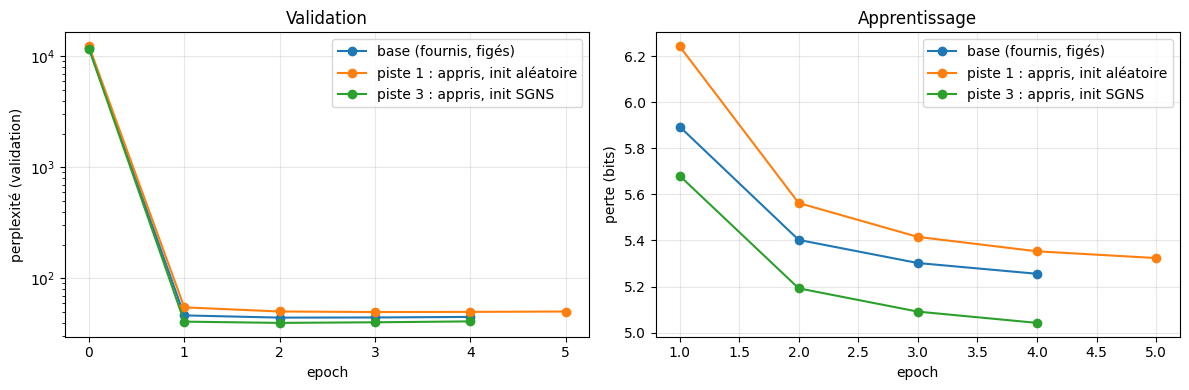

In [17]:
import json, math, os
import matplotlib.pyplot as plt

noms = {"mlp_base": "base (fournis, figés)",
        "mlp_emb_random": "piste 1 : appris, init aléatoire",
        "mlp_emb_sgns": "piste 3 : appris, init SGNS"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m, label in noms.items():
    path = f"resultats/{m}_history.json"
    if not os.path.exists(path):
        continue
    h = json.load(open(path))["history"]
    ep = [e["epoch"] for e in h]
    axes[0].plot(ep, [math.exp(e["val"]) for e in h], marker="o", label=label)
    tr = [e for e in h if e["train"] is not None]
    axes[1].plot([e["epoch"] for e in tr], [e["train"] / math.log(2) for e in tr], marker="o", label=label)
axes[0].set(xlabel="epoch", ylabel="perplexité (validation)", yscale="log", title="Validation")
axes[1].set(xlabel="epoch", ylabel="perte (bits)", title="Apprentissage")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("resultats/courbes_val.png", dpi=150)
plt.show()